# Steam Game Recommender - Modeling & Evaluation

This notebook develops and evaluates recommendation models using the prepared Steam user-game interaction dataset.

The modeling workflow includes popularity-based recommendations, collaborative filtering, content-based filtering, and ranking evaluation.

## 1. Load Prepared Dataset


In [ ]:
#Load
import pandas as pd
import numpy as np
from pathlib import Path

#Path to processed data
DATA_PATH = Path("../data/processed/sampled_reviews.parquet") #file path that works across operating systems

#Load user-game interactions
df = pd.read_parquet(DATA_PATH)

#Inspect dataset
print("Shape:", df.shape)
print("\nColumns:", df.columns.to_list())

df.head()   #initial 624k interactions, 8 features

Shape: (642760, 8)

Columns: ['app_id', 'helpful', 'funny', 'date', 'is_recommended', 'hours', 'user_id', 'review_id']


is_recommended
True     559708
False     83052
Name: count, dtype: int64

## 2. Prepare Interactions & Train/Test Split


In [ ]:
#ONLY Keep reviews where the user recommended the game
positive_df = df[df['is_recommended']==True].copy()

print('Positive interactions:', len(positive_df))
print('Unique users:', positive_df['user_id'].nunique())

Positive interactions: 559708
Unique users: 50000


### 2.1 Leave-one-out split

In [17]:
# Sort positive reviews by user and review date (recent date first)
positive_df = positive_df.sort_values(
    ["user_id", "date", "review_id"]
)

#Select last (most recent) positive review for each user (so 50k reviews)
test_df = positive_df.groupby('user_id').tail(1).copy()

#Everything else becomes training data
train_df = positive_df.drop(index=test_df.index).copy()

print("Training interactions:", len(train_df))
print("Testing interactions:", len(test_df))
print("Training users:", train_df["user_id"].nunique())
print("Testing users:", test_df["user_id"].nunique())

Training interactions: 509708
Testing interactions: 50000
Training users: 50000
Testing users: 50000


### 2.2 Verify the train/test split

In [ ]:
# Confirm every user has exactly one held-out game
assert test_df["user_id"].nunique() == len(test_df)

# Confirm every test user also appears in training
assert set(test_df["user_id"]).issubset(set(train_df["user_id"]))

# Confirm NO reviews appear in BOTH datasets
assert set(train_df["review_id"]).isdisjoint(set(test_df["review_id"]))

print("Train/test split verified!")


Train/test split verified!


## II )Modeling Section

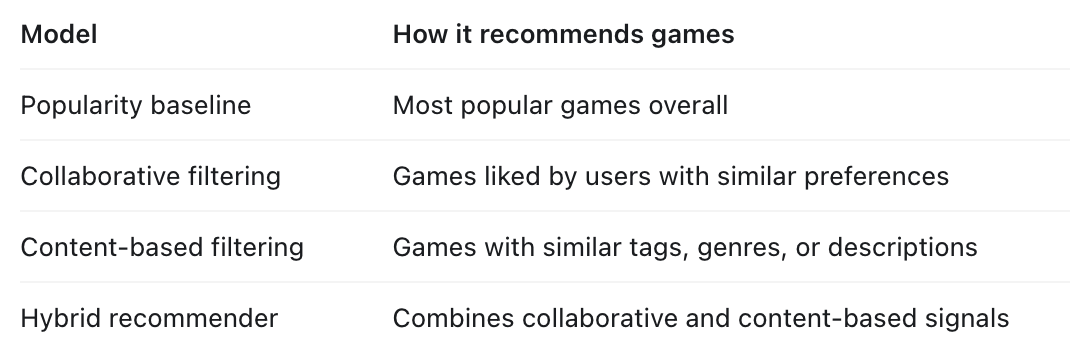

## 3. Popularity-Based Baseline

In [ ]:
#Count positive training reviews for each game 
popular_games = train_df['app_id'].value_counts()
    
display(popular_games.head(10))

app_id
440        3329
292030     2394
374320     2367
1091500    2127
550        2106
431960     2048
377160     2045
620        2021
945360     1846
49520      1822
Name: count, dtype: int64

### 3.2 Generate recommendations

In [ ]:
#Recommend function for specific user based on globally popular games

def recommend_popular(user_id, train_df, popular_games, k=10):
    #Find games user has ALREADY positively reviewed
        #set also removes duplicate values and doesn't preserve order
    seen_games = set(
        train_df.loc[train_df['user_id']== user_id, 'app_id'] #select user ROW, app COLUMN
    )

    #Remove previously seen games from popularity ranking
    recommendations = [
        game_id for game_id in popular_games.index
        if game_id not in seen_games
    ]
    #Return only top k games
    return recommendations[:k]

#Test with 1 user
example_user = train_df['user_id'].iloc[0]

recommendations = recommend_popular(
    example_user,train_df,popular_games,k=10
)
print("User:", example_user)
print("Recommended games:", recommendations)

User: 232
Recommended games: [440, 292030, 1091500, 550, 431960, 377160, 620, 945360, 49520, 304930]


Summary: Takes a specific user, finds their already played games, recommend only games (not played) from the top k global most popular games 

## 4. Recommendation Evaluation 

### 4.1 Recall@K Metric

Recall@K measures whether the user's held-out positive game appears among the top K recommendations.

Since each user has one held-out game, Recall@K is either 1 (found) or 0 (not found). The average was taken for these values across users.

In [ ]:
def recall_at_k(recommendations, actual_game):
    #return 1 if the held-out game appears in the recommendations
    if actual_game in recommendations:
        return 1
    else:
        return 0

#Test with example
example_recommendations = [10,20,30,40,50]

print(recall_at_k(example_recommendations[:3],20)) #1 b/c game 20 was found in subset
print(recall_at_k(example_recommendations[:3],50)) #0 b/c game 50 not found


1
0


### 4.2 NDCG@K (Normalized Discounted Cumulative Gain)

In [60]:
def ndcg_at_k(recommendations, actual_game):
    #Check whether the held out game was recommended
    if actual_game not in recommendations:
        return 0.0

    #Find its position (use +1 b/c index starts at 0)
    rank = recommendations.index(actual_game) + 1

    #Higher-ranked games receive higher score
    return 1 / np.log2(rank + 1)

# Test with example recommendations
example_recommendations = [10, 20, 30, 40, 50]

print(ndcg_at_k(example_recommendations, 10))  # 1.0
print(ndcg_at_k(example_recommendations, 30))  # 0.5
print(ndcg_at_k(example_recommendations, 50))  # ~0.387
print(ndcg_at_k(example_recommendations, 99))  # 0.0

1.0
0.5
0.38685280723454163
0.0


### 4.3 Evaluate Popularity Baseline

Evaluate the popularity-based recommender using Recall@10 and NDCG@10 across all test users.

Recommendations are generated from training data only, excluding previously reviewed games. The held-out positive game for each user serves as the evaluation target.

In [ ]:
#Store each user's training games in a dictionary of sets
user_history = (
    train_df.groupby('user_id')['app_id'].agg(set).to_dict()
)   #ex) user {232: {600, 3230...etc game id's}}

#Store the popularity ranking as a list
popular_game_ids = popular_games.index.tolist()

#Check one user's history
example_user = test_df['user_id'].iloc[0]

print("User:", example_user)
print("Training games:", user_history[example_user])

User: 232
Training games: {335300, 601150, 485510, 627270, 6020, 870780, 814380, 254700, 544750, 374320, 1145360, 32370, 6000, 976310, 1240440, 570940, 883710}


In [67]:
#Update the recommendation function
def recommend_popular_fast(user_id, user_history, popular_game_ids, k=10):
    #Retrieve the user's previously reviewed games
    seen_games = user_history.get(user_id, set())   #if not in dict, return empty set

    recommendations = []

    #Iterate through games from most to least popular
    for game_id in popular_game_ids:
        if game_id not in seen_games:
            recommendations.append(game_id)

        #Stop once we have k recommendations
        if len(recommendations)== k:
            break
        
    return recommendations

In [ ]:
#Evaluate all users
recall_scores = []
ndcg_scores = []

#loop -> create tuples of (user_id, game)
for user_id, actual_game in test_df[['user_id','app_id']].itertuples(
    index=False, name=None):
    #Generate top 10 recommendations
    recommendations = recommend_popular_fast(
        user_id, user_history, popular_game_ids, k=10
    )
    #Compare recommendations against held-out game
    recall_scores.append(recall_at_k(recommendations,actual_game))
    ndcg_scores.append(ndcg_at_k(recommendations, actual_game))

#Average scores across all test users
popularity_recall = np.mean(recall_scores)
popularity_ndcg = np.mean(ndcg_scores)

print(f"Popularity Recall@10: {popularity_recall:.4f}")
print(f"Popularity NDCG@10: {popularity_ndcg:.4f}")

Popularity Recall@10: 0.0359
Popularity NDCG@10: 0.0170


In [ ]:
model_results = []

model_results.append({
    "Model": "Popularity Baseline",
    "Recall@10": popularity_recall,
    "NDCG@10": popularity_ndcg
})

pd.DataFrame(model_results)


,Model,Recall@10,NDCG@10
0,Popularity Baseline,0.03586,0.016967


**Popularity Baseline — Interpretation:** Our evaluation tests whether a recommender can recover each user's last positively reviewed game, which was intentionally held out. However, the popularity model simply recommends the 10 most popular games the user hasn't already positively reviewed in training!, without learning their preferences, so expected low scoring.

Recall@10 = 3.59% means only 3.59% of users had their held-out game appear in their top 10 recommendations. Although this doesn't measure actual user satisfaction or personalized prediction quality, it provides a useful baseline. Future collaborative filtering models can be compared against it to determine whether learning user preferences improves recommendation performance.